<a href="https://colab.research.google.com/github/Ridzzz0Alam/fake-news-detection-system/blob/main/fake_news_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fake and Real News Classification with Leakage Analysis

This notebook works through the ISOT Fake and Real News dataset from the University of Victoria as published on Kaggle. The real articles were collected from Reuters and the fake articles come from unreliable sites flagged by PolitiFact. We build the label ourselves and then train a classifier. The main goal is not only to get a high score but also to understand where that score comes from.

The notebook is organised in six parts.

1. Loading the data and exploring it with attention to duplicates and empty rows and distributions per class
2. A TF-IDF and Logistic Regression baseline on title plus text
3. An investigation of why the baseline is so good followed by removal of the leaking artifacts
4. A comparison of several classifiers on the cleaned data with stratified k-fold cross validation
5. End to end hyperparameter tuning and a title versus text feature set experiment
6. A bonus section that replaces TF-IDF with pretrained dense text representations

In [1]:
import os, re, time, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'   # also silences warnings inside parallel workers
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.linear_model import LogisticRegression, PassiveAggressiveClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid', palette='deep')
RANDOM_STATE = 42
DATA_DIR = Path('.')   # folder that holds True.csv and Fake.csv

## 1. Loading the data and exploring it

### 1.1 Load both files and build the label

Each file is read separately and tagged with a label. We use 1 for fake and 0 for real so that the positive class in precision and recall is the fake class. This is the class a fact checking system would want to catch. The two frames are then concatenated and shuffled with a fixed seed so that results are reproducible.

In [2]:
true_df = pd.read_csv(DATA_DIR / 'True.csv')
fake_df = pd.read_csv(DATA_DIR / 'Fake.csv')
print('True.csv  ', true_df.shape)
print('Fake.csv  ', fake_df.shape)
true_df['label'] = 0
fake_df['label'] = 1

raw = (pd.concat([true_df, fake_df], ignore_index=True)
         .sample(frac=1, random_state=RANDOM_STATE)
         .reset_index(drop=True))
raw['class'] = raw['label'].map({0: 'real', 1: 'fake'})

print('Merged    ', raw.shape)
display(raw['class'].value_counts().to_frame('articles'))
raw.head()

True.csv   (21417, 4)
Fake.csv   (23481, 4)
Merged     (44898, 6)


,articles
class,
fake,23481
real,21417


,title,text,subject,date,label,class
0,"BREAKING: GOP Chairman Grassley Has Had Enough, DEMANDS Trump Jr. Testimony","Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by th...",News,"July 21, 2017",1,fake
1,Failed GOP Candidates Remembered In Hilarious Mocking Eulogies (VIDEO),"Now that Donald Trump is the presumptive GOP nominee, it s time to remember all those other candidates who tried so ...",News,"May 7, 2016",1,fake
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY Trolling Him For Being A Homophobic Bigot,"Mike Pence is a huge homophobe. He supports ex-gay conversion therapy, opposes hate crimes protections for LGBTQ peo...",News,"December 3, 2016",1,fake
3,California AG pledges to defend birth control insurance coverage,SAN FRANCISCO (Reuters) - California Attorney General Xavier Becerra said on Friday he was “prepared to take whateve...,politicsNews,"October 6, 2017",0,real
4,AZ RANCHERS Living On US-Mexico Border Destroy Nancy Pelosi’s Claim About Trump Being “Weak” For Wanting Border Wall...,Twisted reasoning is all that comes from Pelosi these days especially when in 2006 most prominent Democrats voted to...,politics,"Apr 25, 2017",1,fake


### 1.2 Empty rows and malformed rows

We check for missing values and for text fields that are empty or only whitespace. We also check whether the date column parses as a date because a handful of rows in scraped data often have shifted columns.

In [3]:
raw['title'] = raw['title'].fillna('').astype(str)
raw['text'] = raw['text'].fillna('').astype(str)
raw['empty_text'] = raw['text'].str.strip().eq('')
raw['empty_title'] = raw['title'].str.strip().eq('')
raw['date_parsed'] = pd.to_datetime(raw['date'].str.strip(), errors='coerce', format='mixed')
raw['bad_date'] = raw['date_parsed'].isna()

print(raw[['title', 'text', 'subject', 'date']].isna().sum().to_dict())
display(raw.groupby('class')[['empty_text', 'empty_title', 'bad_date']].sum())
print('Examples of unparseable dates')
display(raw.loc[raw.bad_date, ['title', 'date', 'class']].head())
print('Examples of empty text rows')
display(raw.loc[raw.empty_text, ['title', 'subject', 'class']].head())

{'title': 0, 'text': 0, 'subject': 0, 'date': 0}


,empty_text,empty_title,bad_date
class,,,
fake,630,0,10
real,1,0,0


Examples of unparseable dates


,title,date,class
13550,https://100percentfedup.com/12-yr-old-black-conservative-whose-video-to-obama-went-viral-do-you-really-love-america-...,https://100percentfedup.com/12-yr-old-black-conservative-whose-video-to-obama-went-viral-do-you-really-love-america-...,fake
16730,https://fedup.wpengine.com/wp-content/uploads/2015/04/entitled.jpg,https://fedup.wpengine.com/wp-content/uploads/2015/04/entitled.jpg,fake
18327,https://fedup.wpengine.com/wp-content/uploads/2015/04/hillarystreetart.jpg,https://fedup.wpengine.com/wp-content/uploads/2015/04/hillarystreetart.jpg,fake
18825,https://100percentfedup.com/video-hillary-asked-about-trump-i-just-want-to-eat-some-pie/,https://100percentfedup.com/video-hillary-asked-about-trump-i-just-want-to-eat-some-pie/,fake
20827,Homepage,MSNBC HOST Rudely Assumes Steel Worker Would Never Let His Son Follow in His Footsteps…He Couldn’t Be More Wrong [Vi...,fake


Examples of empty text rows


,title,subject,class
19,FATHER OF BENGHAZI VICTIM TY WOODS SPEAKS UP AGAINST HILLARY: “My son would still be alive…” [Video],politics,fake
24,LIVE FEED: INAUGURATION 2017!,politics,fake
124,HOUSE INTEL CHAIR On Trump-Russia Fake Story: “No evidence of anything” [Video],Government News,fake
176,DONALD TRUMP TIME PERSON OF THE YEAR: “The revolution he stirred feels fully American”,politics,fake
280,CNN CONTRIBUTOR: Trump’s Diversity Coalition ‘Mediocre Negroes’ ‘Dragged In’ ‘As a Photo-Op’ [VIDEO],politics,fake


Almost all empty text rows belong to the fake class. These are mostly headline only posts and video posts where the scraper collected no body. Keeping them would teach the model that an empty body means fake. That is a property of the scraping process and not of the news itself so we drop them. The rows with unparseable dates hold URLs in the date column which means the row is malformed and we drop them too.

### 1.3 Exact duplicates

We look for duplicates at three levels. These are identical rows and identical text and identical title. We also build a normalised version of the text that is lower case with URLs and punctuation and extra spaces removed. Two articles that differ only in spacing or punctuation then count as the same article.

In [4]:
def normalise(s):
    s = s.lower()
    s = re.sub(r'https?://\S+|www\.\S+|pic\.twitter\.com/\S+', ' ', s)
    s = re.sub(r'[^a-z0-9 ]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

work = raw[~raw.empty_text & ~raw.bad_date].copy()
work['norm_text'] = work['text'].map(normalise)

dup_summary = pd.DataFrame({
    'identical rows': work.groupby('class').apply(lambda g: g.duplicated(['title', 'text', 'subject', 'date']).sum()),
    'identical text': work.groupby('class').apply(lambda g: g.duplicated('text').sum()),
    'identical title': work.groupby('class').apply(lambda g: g.duplicated('title').sum()),
    'identical normalised text': work.groupby('class').apply(lambda g: g.duplicated('norm_text').sum()),
})
display(dup_summary)

cross = set(work.loc[work.label == 0, 'norm_text']) & set(work.loc[work.label == 1, 'norm_text'])
print('Normalised texts that appear in both classes', len(cross))

# the same fake article is often posted under several subjects
dup_text = work[work.duplicated('norm_text', keep=False) & (work.label == 1)]
print('Subjects seen for one repeated fake article')
display(dup_text.groupby('norm_text')['subject'].apply(lambda s: sorted(set(s))).value_counts().head())

,identical rows,identical text,identical title,identical normalised text
class,,,,
fake,3,5394,5390,5449
real,206,225,591,495


Normalised texts that appear in both classes 0
Subjects seen for one repeated fake article


,count
subject,
"[left-news, politics]",3057
"[Middle-east, US_News]",778
"[Government News, politics]",522
"[Government News, left-news, politics]",454
"[Government News, left-news]",85


The fake file contains many more duplicates than the real file. A large share of them is the same article stored twice under two subject tags such as politics and left-news. Fully identical rows are rare because the subject or date differ.

### 1.4 Near duplicates

Exact matching misses articles that were republished with a small edit such as a new image credit or an extra sentence. To find them we represent every article with TF-IDF and compute the cosine similarity of each article with every other article in chunks. Any pair above a similarity threshold is treated as a near duplicate.

In [5]:
def near_duplicate_pairs(texts, threshold=0.9, chunk=2000):
    vec = TfidfVectorizer(stop_words='english', max_df=0.5, min_df=2,
                          max_features=60000, dtype=np.float32)
    X = vec.fit_transform(texts)
    pairs = []
    for start in range(0, X.shape[0], chunk):
        sims = (X[start:start + chunk] @ X.T).toarray()
        for i in range(sims.shape[0]):
            sims[i, :start + i + 1] = 0          # keep only pairs (i, j) with j > i
        r, c = np.where(sims >= threshold)
        pairs += list(zip(r + start, c, sims[r, c]))
    return pd.DataFrame(pairs, columns=['i', 'j', 'sim'])

# exact duplicates of normalised text are removed first so that only true near duplicates remain
uniq = work.drop_duplicates('norm_text').reset_index(drop=True)
t0 = time.time()
all_pairs = near_duplicate_pairs(uniq['norm_text'], threshold=0.8)
print(f'similarity computed in {time.time() - t0:.0f} s')
for th in [0.8, 0.9, 0.95, 0.99]:
    print(f'pairs with cosine similarity >= {th}  {(all_pairs.sim >= th).sum()}')
pairs = all_pairs[all_pairs.sim >= 0.9].copy()

pairs['label_i'] = uniq.loc[pairs.i, 'label'].values
pairs['label_j'] = uniq.loc[pairs.j, 'label'].values
print('Pairs inside the real class ', ((pairs.label_i == 0) & (pairs.label_j == 0)).sum())
print('Pairs inside the fake class ', ((pairs.label_i == 1) & (pairs.label_j == 1)).sum())
print('Pairs across classes        ', (pairs.label_i != pairs.label_j).sum())

ex = pairs.sort_values('sim').iloc[len(pairs) // 2]
print(f'\nExample pair with similarity {ex.sim:.3f}')
print('A', uniq.loc[ex.i, 'text'][:300])
print('B', uniq.loc[ex.j, 'text'][:300])

similarity computed in 121 s
pairs with cosine similarity >= 0.8  1095
pairs with cosine similarity >= 0.9  336
pairs with cosine similarity >= 0.95  160
pairs with cosine similarity >= 0.99  27
Pairs inside the real class  172
Pairs inside the fake class  160
Pairs across classes         4

Example pair with similarity 0.947
A Tune in to the Alternate Current Radio Network (ACR) for another LIVE broadcast of  The Boiler Room  tonight 6:00 PM PST | 8:00 PM CST | 9:00 PM EST for this special broadcast. Join us for uncensored, uninterruptible talk radio, custom-made for bar fly philosophers, misguided moralists, masochists, 
B Tune in to the Alternate Current Radio Network (ACR) for another LIVE broadcast of  The Boiler Room  tonight 6:00 PM PST | 8:00 PM CST | 9:00 PM EST for this special broadcast. Join us for uncensored, uninterruptible talk radio, custom-made for bar fly philosophers, misguided moralists, masochists, 


### 1.5 Decision on duplicates

We remove exact duplicates of the normalised text and we remove near duplicates above a cosine similarity of 0.9. For each near duplicate pair inside one class we keep the first article and drop the second. When a pair crosses the two classes the label is contradictory and we drop both articles.

The reason is evaluation honesty. If two copies of an article land on different sides of the train and test split the model is tested on text it has already seen. The score then measures memorisation rather than generalisation. Duplicates also give extra weight to the stories that a site happened to repost. The threshold of 0.9 is strict enough that the pairs we checked by hand are clearly the same story with only cosmetic edits.

In [6]:
drop_idx = set(pairs.loc[pairs.label_i == pairs.label_j, 'j'])
cross_pairs = pairs[pairs.label_i != pairs.label_j]
drop_idx |= set(cross_pairs.i) | set(cross_pairs.j)

df = uniq.drop(index=list(drop_idx)).reset_index(drop=True)
df = df.drop(columns=['empty_text', 'empty_title', 'bad_date'])

steps = pd.DataFrame({'articles': [len(raw), len(work), len(uniq), len(df)]},
                     index=['raw merge', 'after empty and malformed rows', 'after exact duplicates', 'after near duplicates'])
display(steps)
display(df['class'].value_counts().to_frame('articles'))

,articles
raw merge,44898
after empty and malformed rows,44257
after exact duplicates,38313
after near duplicates,38058


,articles
class,
real,20811
fake,17247


### 1.6 Article length per class

We count words in the title and in the body. Length is a simple signal that a classifier can pick up so it is worth knowing how different the classes are.

class                 fake     real
title_words count  17247.0  20811.0
            mean      14.3     10.0
            std        3.9      1.7
            min        3.0      4.0
            25%       12.0      9.0
            50%       14.0     10.0
            75%       16.0     11.0
            max       42.0     20.0
text_words  count  17247.0  20811.0
            mean     424.4    382.6
            std      348.3    270.2
            min        1.0     22.0
            25%      279.0    147.0
            50%      377.0    358.0
            75%      503.0    519.0
            max     8135.0   5172.0

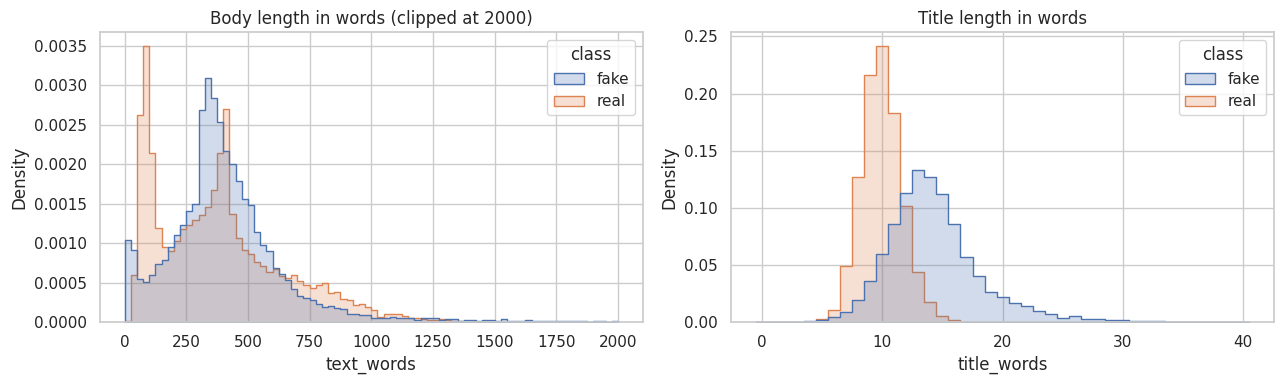

Mean share of all caps words in the title
{'fake': 0.187, 'real': 0.038}


In [7]:
df['title_words'] = df['title'].str.split().str.len()
df['text_words'] = df['text'].str.split().str.len()
display(df.groupby('class')[['title_words', 'text_words']].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x='text_words', hue='class', bins=80, binrange=(0, 2000),
             element='step', stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('Body length in words (clipped at 2000)')
sns.histplot(data=df, x='title_words', hue='class', discrete=True, binrange=(0, 40),
             element='step', stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Title length in words')
plt.tight_layout(); plt.show()

caps = df['title'].map(lambda s: sum(w.isupper() and len(w) > 1 for w in s.split()) / max(len(s.split()), 1))
print('Mean share of all caps words in the title')
print(caps.groupby(df['class']).mean().round(3).to_dict())

The body length distributions overlap a lot and the medians are almost the same. The real class shows a clear peak of short wire briefs under about 150 words so its lower quartile is much lower. The fake class has a small group of almost empty posts and the most extreme outliers of several thousand words. Titles are a clearer difference. Fake titles are longer and use far more words in capitals. TF-IDF lower cases the text by default so the capitals themselves will not reach the model but the extra words will.

### 1.7 Subject and date per class

class,fake,real
subject,,
Government News,882,0
Middle-east,382,0
News,9047,0
US_News,389,0
left-news,2356,0
politics,4191,0
politicsNews,0,10994
worldnews,0,9817


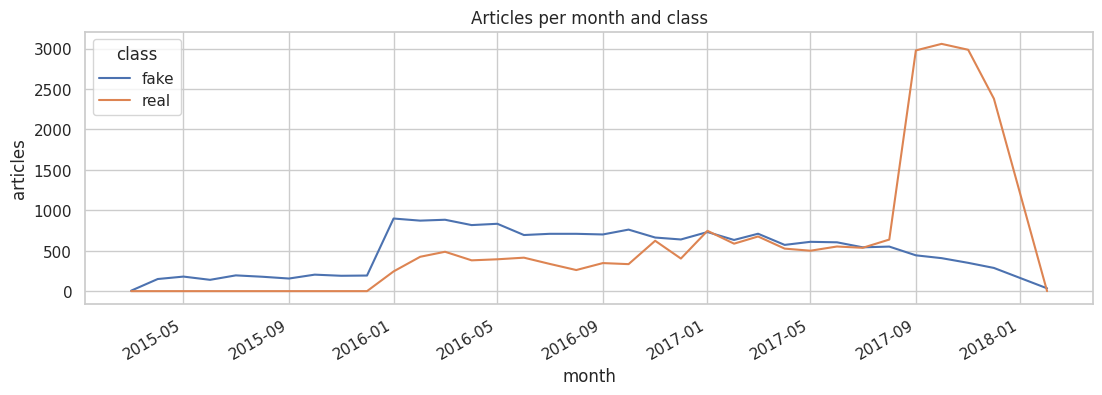

Date range per class


,min,max
class,,
fake,2015-03-31,2018-02-19
real,2016-01-13,2017-12-31


class,fake,real
date,,
abbreviated month,8273,0
full month,8974,0
trailing space,0,20811


In [8]:
display(pd.crosstab(df['subject'], df['class']))

monthly = (df.assign(month=df.date_parsed.dt.to_period('M').dt.to_timestamp())
             .groupby(['month', 'class']).size().unstack(fill_value=0))
ax = monthly.plot(figsize=(13, 4), title='Articles per month and class')
ax.set_ylabel('articles'); plt.show()

print('Date range per class')
display(df.groupby('class')['date_parsed'].agg(['min', 'max']))

# the raw date strings are written in different styles by the two sources
style = df['date'].map(lambda s: 'trailing space' if s.endswith(' ') else
                       ('abbreviated month' if re.match(r'^[A-Z][a-z]{2} \d', s) else 'full month'))
display(pd.crosstab(style, df['class']))

These two tables already reveal two serious problems.

The subject values do not overlap at all. Real articles are tagged only as politicsNews or worldnews and fake articles use six other tags. Subject is therefore a perfect proxy for the label and any model that sees it can score 100 percent without reading a word.

The date column leaks in two ways. The real articles cover January 2016 to December 2017 while the fake articles start in 2015 and run into 2018 so the time window alone separates a share of the data. The raw date strings are also formatted differently since real dates end with a trailing space while many fake dates use abbreviated month names. Both columns describe how the data was collected and we will exclude them from the features.

## 2. Baseline with TF-IDF and Logistic Regression

We combine title and text into one string and split the data into 80 percent train and 20 percent test with stratification on the label. Stratification keeps the class ratio the same in both parts. The vectorizer lives inside a scikit-learn Pipeline so it is fitted on the training data only and the test set never influences the vocabulary or the IDF weights.

train 30446  test 7612
trained in 66.0 s
Baseline on raw title+text accuracy=0.9950 precision=0.9974 recall=0.9916 f1=0.9945


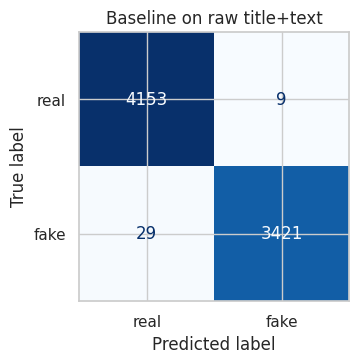

              precision    recall  f1-score   support

        real     0.9931    0.9978    0.9954      4162
        fake     0.9974    0.9916    0.9945      3450

    accuracy                         0.9950      7612
   macro avg     0.9952    0.9947    0.9950      7612
weighted avg     0.9950    0.9950    0.9950      7612



In [9]:
df['content'] = df['title'] + ' ' + df['text']
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=df['label'],
                                       random_state=RANDOM_STATE)
y_train, y_test = df.loc[train_idx, 'label'], df.loc[test_idx, 'label']
print('train', len(train_idx), ' test', len(test_idx))

def evaluate(name, y_true, y_pred, show_cm=True):
    scores = {'accuracy': accuracy_score(y_true, y_pred),
              'precision': precision_score(y_true, y_pred),
              'recall': recall_score(y_true, y_pred),
              'f1': f1_score(y_true, y_pred)}
    print(name, ' '.join(f'{k}={v:.4f}' for k, v in scores.items()))
    if show_cm:
        fig, ax = plt.subplots(figsize=(4, 3.5))
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                               display_labels=['real', 'fake']).plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(name); plt.show()
    return scores

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9,
                              max_features=100000, sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=2000, C=10)),
])
t0 = time.time()
baseline.fit(df.loc[train_idx, 'content'], y_train)
print(f'trained in {time.time() - t0:.1f} s')
base_pred = baseline.predict(df.loc[test_idx, 'content'])
results = {'baseline (raw title+text)': evaluate('Baseline on raw title+text', y_test, base_pred)}
print(classification_report(y_test, base_pred, target_names=['real', 'fake'], digits=4))

The baseline is close to perfect. Results this high on a task as hard as fake news detection are a warning sign rather than a success. Real fact checking is difficult even for trained people so a bag of words model this accurate is almost certainly reading something other than the truthfulness of the claims. The next part finds out what that is.

## 3. Why is the baseline so good

### 3.1 Top weighted features

In Logistic Regression a large positive weight pushes a prediction towards fake and a large negative weight pushes it towards real. Looking at the extremes shows what the model relies on most.

In [10]:
def top_features(pipe, n=25):
    names = np.array(pipe.named_steps['tfidf'].get_feature_names_out())
    coef = pipe.named_steps['clf'].coef_.ravel()
    order = np.argsort(coef)
    return pd.DataFrame({'real feature': names[order[:n]], 'real weight': coef[order[:n]].round(2),
                         'fake feature': names[order[::-1][:n]], 'fake weight': coef[order[::-1][:n]].round(2)})

display(top_features(baseline))

,real feature,real weight,fake feature,fake weight
0,reuters,-32.25,via,17.56
1,said,-18.61,video,15.03
2,washington reuters,-14.56,read more,10.37
3,said on,-13.00,image,9.01
4,washington,-9.23,read,8.92
5,reuters the,-9.14,featured image,8.71
6,on wednesday,-8.96,just,8.69
7,on tuesday,-8.72,featured,8.61
8,president donald,-8.16,this,8.50
9,said in,-8.14,obama,8.39


The strongest real features are the word reuters and phrases like washington reuters and told reuters. These come from the dateline that opens almost every Reuters story. The strongest fake features include via and featured image and getty images and pic twitter and read more. These are image credits and embedded tweet links and page furniture from the fake news websites. None of them say anything about whether a story is true. They identify the publisher.

### 3.2 Searching for source identifying strings

We now search the raw text directly for patterns that identify the source. For each pattern we report the share of articles in each class that contain it.

In [11]:
probes = {
    'Reuters dateline  CITY (Reuters) -': r'^.{0,150}?\(Reuters\)\s*-',
    'word Reuters anywhere': r'\bReuters\b',
    'Trump tweet boilerplate': r'The following statements?\s+(?:was|were)\s+posted',
    'tweet timestamp like [0930 EST]': r'\[\s*\d{3,4}\s*(?:EST|EDT)\s*\]',
    'Source link marker': r'Source link',
    'Featured image': r'Featured image',
    'Getty Images': r'Getty Images',
    'image or photo credit': r'\b(?:[Ii]mage|[Pp]hoto) (?:via|credit|by|courtesy)',
    'screengrab or screenshot': r'(?i)screen ?(?:grab|shot|capture)',
    'pic.twitter.com link': r'pic\.twitter\.com',
    'any URL': r'https?://|www\.',
    'Twitter handle @name': r'@\w+',
    'Via at line or sentence start': r'(?:^|[.!?\s])Via:? ',
    'Read more': r'(?i)\bread more\b',
    '21st Century Wire': r'21st Century Wire|21WIRE',
    'title tag like (VIDEO) or [WATCH]': None,
    'title starts with WATCH or BREAKING': None,
}
rows = []
for name, pat in probes.items():
    if name.startswith('title tag'):
        hit = df['title'].str.contains(r'[\(\[]\s*(?:VIDEO|VIDEOS|TWEET|TWEETS|IMAGE|IMAGES|PHOTO|PHOTOS|WATCH|AUDIO|DETAILS|GRAPHIC)', case=False, regex=True)
    elif name.startswith('title starts'):
        hit = df['title'].str.contains(r'^\s*(?:WATCH|BREAKING|JUST IN|LOL|WOW|BOOM)\b', regex=True)
    else:
        hit = df['text'].str.contains(pat, regex=True)
    rows.append({'pattern': name,
                 'real %': 100 * hit[df.label == 0].mean(),
                 'fake %': 100 * hit[df.label == 1].mean()})
probe_table = pd.DataFrame(rows).set_index('pattern').round(2)
display(probe_table)

print('Typical openings of real articles')
for s in df.loc[df.label == 0, 'text'].sample(5, random_state=1): print('  ', s[:90])
print('Typical endings of fake articles')
for s in df.loc[df.label == 1, 'text'].sample(5, random_state=3): print('  ', s[-110:])

,real %,fake %
pattern,,
Reuters dateline CITY (Reuters) -,99.01,0.00
word Reuters anywhere,99.85,1.18
Trump tweet boilerplate,0.45,0.00
tweet timestamp like [0930 EST],0.45,0.00
Source link marker,0.46,0.00
Featured image,0.00,42.25
Getty Images,0.00,22.81
image or photo credit,0.00,42.88
screengrab or screenshot,0.04,17.54


Typical openings of real articles
   WASHINGTON (Reuters) - The White House on Saturday accused the media of framing photograph
   WASHINGTON (Reuters) - U.S. President Donald Trump tweeted early on Friday that “Iran is p
   WASHINGTON (Reuters) - The three top Democrats in the U.S. House of Representatives  calle
   NEW YORK (Reuters) - Latino groups have criticized the Democratic Party for relying too he
   FRANKFURT/WASHINGTON (Reuters) - Some Democratic members of the U.S. Congress have renewed
Typical endings of fake articles
   regulations Continue this story at Sovereign ManREAD MORE OBAMACARE NEWS AT: 21st Century Wire Obamacare Files
   atives sure showed us with their MAGA and Pepe memes, didn t they?Read more:Photo by Sean Rayford/Getty Images
   people, even by the standards of anti-government terrorists.Featured image via video screen capture from MSNBC
   y if he doesn t get other countries to destroy us with nukes first.Featured image via Win McNamee/Getty Images
   eir 

The table confirms the pattern. Nearly every real article contains the word Reuters and most open with the dateline while fake articles almost never do. The image credits and tweet links and URLs and the Via line exist only in the fake class. Titles of fake articles carry tags such as (VIDEO) and openers such as WATCH or BREAKING which Reuters never uses. A model can lean on any of these strings and reach a high score without learning anything about content.

### 3.3 A model that only sees the subject

To show how much information the metadata carries we train a Logistic Regression on the one hot encoded subject column alone. We also train one on the raw date string treated as character n grams.

Subject only accuracy=1.0000 precision=1.0000 recall=1.0000 f1=1.0000


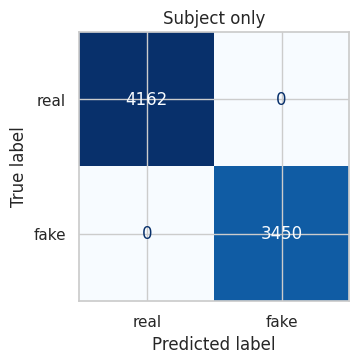

Date string only accuracy=1.0000 precision=1.0000 recall=1.0000 f1=1.0000


In [12]:
subject_model = Pipeline([('ohe', OneHotEncoder(handle_unknown='ignore')),
                          ('clf', LogisticRegression(max_iter=1000))])
subject_model.fit(df.loc[train_idx, ['subject']], y_train)
results['subject only'] = evaluate('Subject only', y_test, subject_model.predict(df.loc[test_idx, ['subject']]))

date_model = Pipeline([('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(1, 4), lowercase=False)),
                       ('clf', LogisticRegression(max_iter=1000))])
date_model.fit(df.loc[train_idx, 'date'], y_train)
results['date string only'] = evaluate('Date string only', y_test, date_model.predict(df.loc[test_idx, 'date']), show_cm=False)

The subject alone gives a perfect score because each subject value belongs to exactly one class. The date string alone also gives a perfect score because the two sources write dates in different formats and cover different periods. This is classic target leakage. These columns would not be available in the same form for a new article from an unknown website so they cannot be used as features.

### 3.4 Stripping the leaking artifacts

The cleaning function below removes the source identifying strings found above. It works on the original text before lower casing so that the patterns stay precise.

1. The Reuters dateline at the start of the article and every remaining mention of the word Reuters
2. The fixed note that Reuters adds before reprinted Trump tweets
3. URLs and pic.twitter.com links and Twitter handles
4. Image and photo credits including Featured image and Getty Images and screengrab notes
5. Via lines and Read more prompts and the 21st Century Wire signature
6. Tags in titles such as (VIDEO) or [TWEETS] and openers such as WATCH or BREAKING and the Reuters title prefixes such as Exclusive and Factbox

We also stop using subject and date. After cleaning we remove articles that became exact duplicates and articles whose body became empty.

In [13]:
TITLE_TAGS = r'[\(\[]\s*(?:VIDEO|VIDEOS|TWEET|TWEETS|IMAGE|IMAGES|PHOTO|PHOTOS|WATCH|AUDIO|DETAILS|GRAPHIC|GRAPHIC VIDEO)[^\)\]]*[\)\]]'
TITLE_OPENERS = r'^\s*(?:WATCH|BREAKING|JUST IN|BREAKING NEWS|LOL|WOW|BOOM|EXCLUSIVE|FACTBOX|FACTBOX|UPDATE \d+|WRAPUP \d+|U\.S\. FACTBOX)\s*[:\-]\s*'

TEXT_RULES = [
    (r'^.{0,150}?\(Reuters\)\s*-\s*', ' '), # dateline
    (r'The following statements?\s+(?:was|were)\s+posted.*?(?:accuracy|ahead)\.', ' '), # tweet boilerplate
    (r'\[\s*\d{3,4}\s*(?:EST|EDT)\s*\]\s*-?', ' '), # tweet timestamps
    (r'Source link\s*:?\s*(?:\([^)]*\))?', ' '), # tweet source markers
    (r'(?i)(?:\[|\()?\s*(?:featured )?(?:image|photo|video)s?\s*(?:/\s*featured image)?\s*(?:via|credit|by|courtesy)\b[^.\n]{0,80}', ' '),
    (r'(?i)featured image[^.\n]{0,80}', ' '),
    (r'Getty Images?', ' '),
    (r'(?i)screen ?(?:grab|shot|capture)s?', ' '),
    (r'https?://\S+|www\.\S+|pic\.twitter\.com/\S+|\b[\w.-]+\.[a-z]{2,6}/\S*', ' '),# any bare domain link such as bit.ly/abc
    (r'@\w+', ' '),
    (r'(?:^|(?<=[.!?\s]))(?:Via|VIA|via)\s*:\s*[^.\n]{0,60}', ' '),
    (r'(?:Via|VIA)\s+[A-Z][\w\s]{0,40}$', ' '),
    (r'(?i)\bread more\s*:?', ' '),
    (r'21st Century Wire|21WIRE', ' '),
    (r'\bReuters\b', ' '),
]
TEXT_RULES = [(re.compile(p, flags=re.S), r) for p, r in TEXT_RULES]

def clean_text(s):
    s = re.sub(r'\s+', ' ', s.replace('\xa0', ' '))
    for pat, rep in TEXT_RULES:
        s = pat.sub(rep, s)
    return re.sub(r'\s+', ' ', s).strip()

def clean_title(s):
    s = re.sub(TITLE_TAGS, ' ', s, flags=re.I)
    s = re.sub(TITLE_OPENERS, ' ', s, flags=re.I)
    s = re.sub(r'\bReuters\b', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

clean = df[['title', 'text', 'label', 'class']].copy()
clean['title'] = clean['title'].map(clean_title)
clean['text'] = clean['text'].map(clean_text)

n0 = len(clean)
clean = clean[clean['text'].str.split().str.len() >= 5]
clean['content'] = clean['title'] + ' ' + clean['text']
clean = clean[~clean['content'].map(normalise).duplicated()]
print(f'{n0 - len(clean)} articles removed after cleaning ({len(clean)} remain)')
display(clean['class'].value_counts().to_frame('articles'))

# re-runing the probes on the cleaned text to confirm the artifacts are gone
check = []
for name, pat in list(probes.items())[:-2]:
    hit = clean['text'].str.contains(pat, regex=True)
    check.append({'pattern': name, 'real % before': probe_table.loc[name, 'real %'],
                  'fake % before': probe_table.loc[name, 'fake %'],
                  'real % after': 100 * hit[clean.label == 0].mean(),
                  'fake % after': 100 * hit[clean.label == 1].mean()})
display(pd.DataFrame(check).set_index('pattern').round(2))

i = clean.index[(clean.label == 0)][0]
print('Real before', df.loc[i, 'text'][:160]); print('Real after ', clean.loc[i, 'text'][:160])
j = clean.index[(clean.label == 1) & df.loc[clean.index, 'text'].str.contains('Featured image')][0]
print('Fake before', df.loc[j, 'text'][-160:]); print('Fake after ', clean.loc[j, 'text'][-160:])

36 articles removed after cleaning (38022 remain)


,articles
class,
real,20811
fake,17211


,real % before,fake % before,real % after,fake % after
pattern,,,,
Reuters dateline CITY (Reuters) -,99.01,0.00,0.0,0.00
word Reuters anywhere,99.85,1.18,0.0,0.00
Trump tweet boilerplate,0.45,0.00,0.0,0.00
tweet timestamp like [0930 EST],0.45,0.00,0.0,0.00
Source link marker,0.46,0.00,0.0,0.00
Featured image,0.00,42.25,0.0,0.00
Getty Images,0.00,22.81,0.0,0.00
image or photo credit,0.00,42.88,0.0,0.01
screengrab or screenshot,0.04,17.54,0.0,0.00


Real before SAN FRANCISCO (Reuters) - California Attorney General Xavier Becerra said on Friday he was “prepared to take whatever action it takes” to defend the Obamacare m
Real after  California Attorney General Xavier Becerra said on Friday he was “prepared to take whatever action it takes” to defend the Obamacare mandate that health insurer
Fake before arly sick of Trump s bullshit, just might be the ones who could save the republic. All they need is a bit of courage.Featured image via Win McNamee/Getty Images
Fake after   that old-timers like Grassley, who are clearly sick of Trump s bullshit, just might be the ones who could save the republic. All they need is a bit of courage.


### 3.5 Retraining on the cleaned data

We split the cleaned data again with the same seed and stratification and train exactly the same pipeline as the baseline. Any drop in score shows how much of the baseline came from the artifacts.

LogReg on cleaned title+text accuracy=0.9892 precision=0.9930 recall=0.9831 f1=0.9880


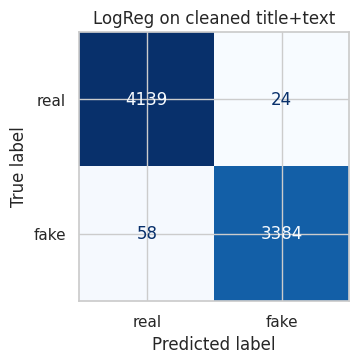

,accuracy,precision,recall,f1
baseline (raw title+text),0.9950,0.9974,0.9916,0.9945
subject only,1.0000,1.0000,1.0000,1.0000
date string only,1.0000,1.0000,1.0000,1.0000
cleaned title+text,0.9892,0.9930,0.9831,0.9880


,real feature,real weight,fake feature,fake weight
0,said,-22.84,this,11.63
1,said on,-16.63,gop,10.99
2,on wednesday,-11.36,president trump,10.75
3,on tuesday,-11.03,just,10.33
4,president donald,-10.67,us,9.51
5,on thursday,-10.13,the us,9.11
6,said in,-9.94,obama,9.10
7,on friday,-9.50,watch,8.83
8,trump on,-9.03,president obama,7.55
9,on monday,-9.02,hillary,7.46


In [14]:
c_train, c_test = train_test_split(clean.index, test_size=0.2, stratify=clean['label'],
                                   random_state=RANDOM_STATE)
Xc_train, Xc_test = clean.loc[c_train, 'content'], clean.loc[c_test, 'content']
yc_train, yc_test = clean.loc[c_train, 'label'], clean.loc[c_test, 'label']

cleaned_lr = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9,
                              max_features=100000, sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=2000, C=10)),
])
cleaned_lr.fit(Xc_train, yc_train)
results['cleaned title+text'] = evaluate('LogReg on cleaned title+text', yc_test, cleaned_lr.predict(Xc_test))
display(pd.DataFrame(results).T.round(4))
display(top_features(cleaned_lr))

After cleaning the score drops a little but stays high. Checking the top features again after every cleaning pass is important. A first version of the link rule only covered .com and .org and .net domains and the shortened bit.ly links inside reprinted tweets then rose to the top of the real features. The rule now removes links on any domain. A second check then surfaced edt and est and source link. These came from about a hundred Reuters posts that reprint presidential tweets with timestamps such as [0930 EST] and a Source link marker. Those markers are now removed as well. The top features are now ordinary words. The real side is led by said and by weekday phrases such as on wednesday and by formal titles. These reflect the house style of a wire agency that reports who said what and on which day. Phrases such as trump on and on twitter come from the same habit since Reuters writes that Trump said something on Twitter on a given day. That is a style cue and not page boilerplate so we keep it. The fake side is led by words such as just and even and this and you and by informal names. These reflect the opinionated and conversational tone of the fake sites.

This is an honest limitation of the dataset. Every real article comes from a single outlet so a classifier can still separate the classes partly by recognising Reuters writing style rather than by judging truthfulness. Removing the obvious artifacts makes the task fairer but does not turn it into true fact checking. A model trained here should be expected to perform worse on real articles from other publishers.

## 4. Comparing classifiers on the cleaned data

We compare four linear classifiers that all receive the same TF-IDF features.

1. Logistic Regression
2. Linear Support Vector Machine
3. Multinomial Naive Bayes
4. Passive Aggressive Classifier

We use stratified 5 fold cross validation on the cleaned training set. To make the comparison fair and quick the TF-IDF matrix is fitted once per fold on that fold's training part and then shared by all classifiers. The vectorizer never sees the validation fold. We record F1 and accuracy on each fold together with the training time of each classifier.

,f1_mean,f1_std,acc_mean,acc_std,train_time_s,F1 (mean ± std)
model,,,,,,
Passive Aggressive,0.9874,0.0019,0.9887,0.0017,0.5707,0.9874 ± 0.0019
Linear SVM,0.9863,0.0012,0.9876,0.0011,1.0506,0.9863 ± 0.0012
Logistic Regression,0.9828,0.0021,0.9845,0.0019,2.1653,0.9828 ± 0.0021
Multinomial NB,0.9454,0.0032,0.9504,0.0028,0.1053,0.9454 ± 0.0032


TF-IDF fitting per fold took 50.3 s on average and is shared by all models


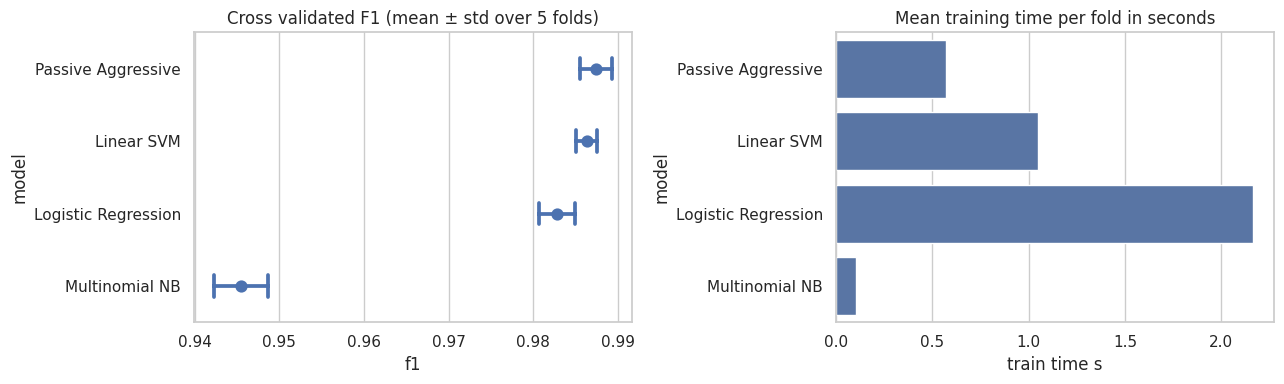

Best model by mean F1 Passive Aggressive


In [15]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=2000, C=10),
    'Linear SVM': lambda: LinearSVC(C=1.0),
    'Multinomial NB': lambda: MultinomialNB(alpha=0.1),
    'Passive Aggressive': lambda: PassiveAggressiveClassifier(max_iter=1000, random_state=RANDOM_STATE),
}

records = []
X_cv, y_cv = Xc_train.reset_index(drop=True), yc_train.reset_index(drop=True)
for fold, (tr, va) in enumerate(skf.split(X_cv, y_cv)):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9,
                          max_features=100000, sublinear_tf=True)
    t0 = time.time()
    A_tr = vec.fit_transform(X_cv[tr]); A_va = vec.transform(X_cv[va])
    vec_time = time.time() - t0
    for name, make in models.items():
        clf = make()
        t0 = time.time(); clf.fit(A_tr, y_cv[tr]); fit_time = time.time() - t0
        pred = clf.predict(A_va)
        records.append({'model': name, 'fold': fold, 'f1': f1_score(y_cv[va], pred),
                        'accuracy': accuracy_score(y_cv[va], pred), 'train time s': fit_time,
                        'vectorize time s': vec_time})

cv_res = pd.DataFrame(records)
summary = (cv_res.groupby('model')
                 .agg(f1_mean=('f1', 'mean'), f1_std=('f1', 'std'),
                      acc_mean=('accuracy', 'mean'), acc_std=('accuracy', 'std'),
                      train_time_s=('train time s', 'mean'))
                 .sort_values('f1_mean', ascending=False))
summary['F1 (mean ± std)'] = summary.apply(lambda r: f'{r.f1_mean:.4f} ± {r.f1_std:.4f}', axis=1)
display(summary.round(4))
print(f"TF-IDF fitting per fold took {cv_res['vectorize time s'].mean():.1f} s on average and is shared by all models")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.pointplot(data=cv_res, y='model', x='f1', order=summary.index, errorbar='sd',
              linestyle='none', capsize=0.3, ax=axes[0])
axes[0].set_title('Cross validated F1 (mean ± std over 5 folds)')
sns.barplot(data=cv_res, y='model', x='train time s', order=summary.index, errorbar=None, ax=axes[1])
axes[1].set_title('Mean training time per fold in seconds')
plt.tight_layout(); plt.show()

best_name = summary.index[0]
print('Best model by mean F1', best_name)

The three margin based linear models are very close to each other. The Passive Aggressive classifier has the highest mean F1 and the linear SVM follows closely with Logistic Regression just behind. The gaps between them are about the size of one standard deviation so they should be read as a near tie rather than a clear win. All three train in well under a second per fold once the TF-IDF matrix exists. Fitting the vectorizer is by far the most expensive step.

Multinomial Naive Bayes is the fastest model but clearly the weakest. It assumes that words are independent given the class and it cannot balance correlated features against each other the way a discriminative model can.

The notebook picks the model with the best mean F1 automatically and tunes it in the next part. Passive Aggressive is an online relative of the linear SVM and its C parameter plays the same role. It limits how far each update may move the weights to fit a misclassified example.

## 5. Tuning and feature set experiments

### 5.1 End to end tuning with RandomizedSearchCV

We tune the best pipeline from Part 4 as one object. The search covers vectorizer parameters and the classifier regularisation strength together because they interact. A larger vocabulary for example may need stronger regularisation. RandomizedSearchCV samples 20 combinations and scores each with stratified 3 fold cross validation on F1. Trigrams were left out of the space because the full trigram vocabulary of more than 30 thousand long articles did not fit in the memory of the machine used here. Randomised search covers a wide space more efficiently than a full grid when some parameters matter much more than others.

In [16]:
def make_classifier(name):
    return {'Logistic Regression': LogisticRegression(max_iter=3000),
            'Linear SVM': LinearSVC(),
            'Multinomial NB': MultinomialNB(),
            'Passive Aggressive': PassiveAggressiveClassifier(max_iter=1000, random_state=RANDOM_STATE)}[name]

search_pipe = Pipeline([('tfidf', TfidfVectorizer(sublinear_tf=True)), ('clf', make_classifier(best_name))])
param_dist = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__max_features': [20000, 50000, 100000, 200000, None],
    'tfidf__min_df': [2, 3, 5],
    'tfidf__max_df': [0.5, 0.7, 0.9, 1.0],
    'tfidf__sublinear_tf': [True, False],
}
if best_name == 'Multinomial NB':
    param_dist['clf__alpha'] = loguniform(1e-3, 1)
else:
    param_dist['clf__C'] = loguniform(1e-2, 1e2)

search = RandomizedSearchCV(search_pipe, param_dist, n_iter=20, scoring='f1',
                            cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                            n_jobs=2, random_state=RANDOM_STATE, return_train_score=False, verbose=1)
t0 = time.time()
search.fit(Xc_train, yc_train)
print(f'search finished in {(time.time() - t0) / 60:.1f} min')
print('Best parameters')
for k, v in search.best_params_.items(): print(f'   {k} = {v}')
print(f'Best mean CV F1 = {search.best_score_:.4f} ± {search.cv_results_["std_test_score"][search.best_index_]:.4f}')

cvr = pd.DataFrame(search.cv_results_)
cols = [c for c in cvr.columns if c.startswith('param_')] + ['mean_test_score', 'std_test_score', 'mean_fit_time']
display(cvr.sort_values('rank_test_score')[cols].head(10).round(4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
search finished in 24.0 min
Best parameters
   clf__C = 0.6071989493441299
   tfidf__max_df = 0.9
   tfidf__max_features = 100000
   tfidf__min_df = 5
   tfidf__ngram_range = (1, 2)
   tfidf__sublinear_tf = True
Best mean CV F1 = 0.9870 ± 0.0012


,param_clf__C,param_tfidf__max_df,param_tfidf__max_features,param_tfidf__min_df,param_tfidf__ngram_range,param_tfidf__sublinear_tf,mean_test_score,std_test_score,mean_fit_time
1,0.6072,0.9,100000,5,"(1, 2)",True,0.9870,0.0012,55.3387
9,0.1654,0.5,50000,5,"(1, 2)",True,0.9866,0.0007,54.2503
19,8.2419,0.5,100000,2,"(1, 2)",True,0.9862,0.0010,49.9829
11,0.0536,1.0,50000,3,"(1, 2)",False,0.9842,0.0005,55.7901
14,0.2024,0.7,200000,2,"(1, 2)",False,0.9839,0.0013,56.6942
12,1.5376,0.7,None,5,"(1, 2)",False,0.9837,0.0012,47.4945
5,2.8016,0.7,200000,5,"(1, 2)",False,0.9835,0.0010,55.4454
6,13.8262,0.9,200000,5,"(1, 2)",False,0.9828,0.0019,55.2476
8,0.0182,1.0,20000,3,"(1, 2)",False,0.9818,0.0013,56.0560
16,0.2673,1.0,200000,2,"(1, 1)",True,0.9814,0.0008,16.5887


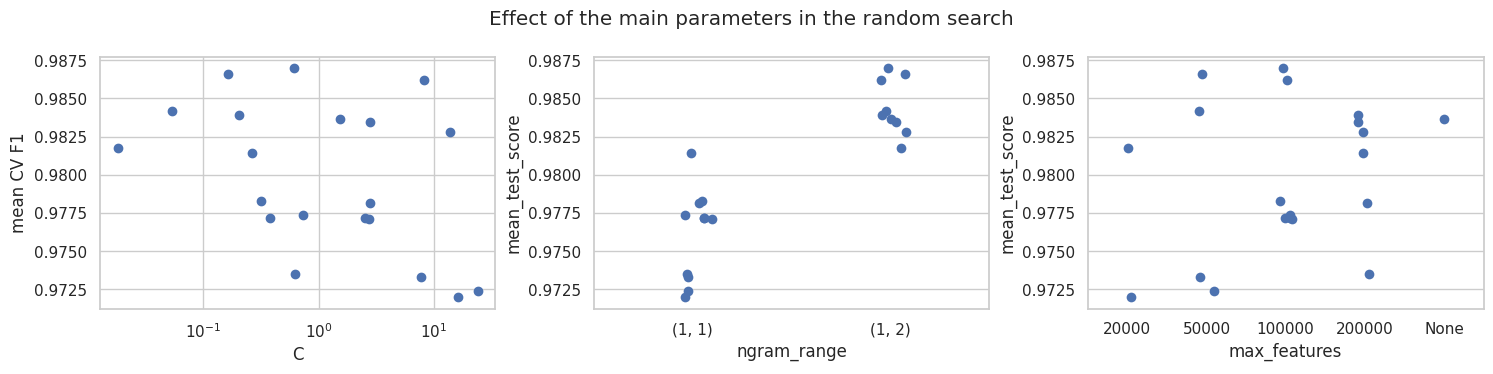

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
reg = 'param_clf__alpha' if 'param_clf__alpha' in cvr else 'param_clf__C'
axes[0].scatter(cvr[reg].astype(float), cvr['mean_test_score'])
axes[0].set_xscale('log'); axes[0].set_xlabel(reg.replace('param_clf__', '')); axes[0].set_ylabel('mean CV F1')
cvr['ngram'] = cvr['param_tfidf__ngram_range'].astype(str)
sns.stripplot(data=cvr, x='ngram', y='mean_test_score', ax=axes[1], size=7)
axes[1].set_xlabel('ngram_range')
cvr['max_feat'] = cvr['param_tfidf__max_features'].astype(str)
sns.stripplot(data=cvr, x='max_feat', y='mean_test_score', ax=axes[2], size=7,
              order=['20000', '50000', '100000', '200000', 'None'])
axes[2].set_xlabel('max_features')
fig.suptitle('Effect of the main parameters in the random search'); plt.tight_layout(); plt.show()

### 5.2 Final evaluation of the tuned model on the held out test set

The test set has not been used for any decision so far. We evaluate the tuned pipeline on it once.

Tuned Passive Aggressive on cleaned test set accuracy=0.9929 precision=0.9945 recall=0.9898 f1=0.9921


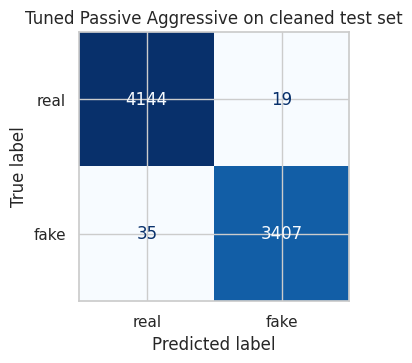

              precision    recall  f1-score   support

        real     0.9916    0.9954    0.9935      4163
        fake     0.9945    0.9898    0.9921      3442

    accuracy                         0.9929      7605
   macro avg     0.9930    0.9926    0.9928      7605
weighted avg     0.9929    0.9929    0.9929      7605



,real feature,real weight,fake feature,fake weight
0,said,-8.61,president trump,5.45
1,said on,-6.54,gop,5.08
2,president donald,-5.18,this,4.82
3,on tuesday,-4.92,the us,4.43
4,on wednesday,-4.83,just,3.96
5,trump on,-4.65,obama,3.92
6,on thursday,-4.41,us,3.74
7,on friday,-4.27,watch,3.74
8,on monday,-4.05,mr,3.71
9,on twitter,-3.94,sen,3.32


In [18]:
best_pipe = search.best_estimator_
tuned_pred = best_pipe.predict(Xc_test)
results['tuned ' + best_name + ' (cleaned)'] = evaluate(f'Tuned {best_name} on cleaned test set', yc_test, tuned_pred)
print(classification_report(yc_test, tuned_pred, target_names=['real', 'fake'], digits=4))
display(top_features(best_pipe, n=20))

### 5.3 Title only versus text only versus title plus text

Finally we ask which part of the article carries the signal. We keep the tuned parameters fixed and change only the input column. Each variant is scored with stratified 5 fold cross validation on the cleaned training set and then once on the test set.

,CV F1 mean,CV F1 std,test F1,mean fit time s
feature set,,,,
title only,0.9237,0.0012,0.9262,2.3636
text only,0.9844,0.0016,0.9894,63.6164
title + text,0.9876,0.0015,0.9921,61.2649


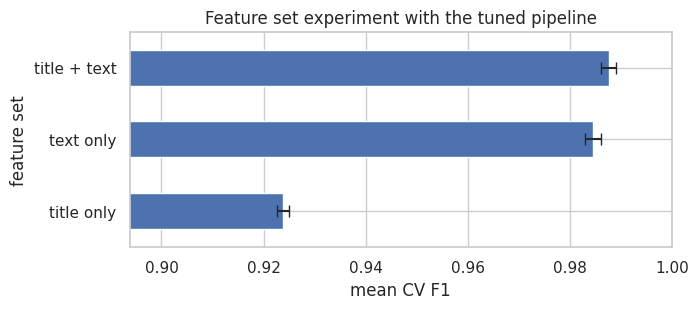

In [19]:
feature_sets = {'title only': 'title', 'text only': 'text', 'title + text': 'content'}
fs_rows = []
for label, col in feature_sets.items():
    pipe = Pipeline([('tfidf', TfidfVectorizer(sublinear_tf=True)), ('clf', make_classifier(best_name))])
    pipe.set_params(**search.best_params_)
    cv = cross_validate(pipe, clean.loc[c_train, col], yc_train, cv=skf, scoring='f1', n_jobs=2)
    pipe.fit(clean.loc[c_train, col], yc_train)
    test_f1 = f1_score(yc_test, pipe.predict(clean.loc[c_test, col]))
    fs_rows.append({'feature set': label, 'CV F1 mean': cv['test_score'].mean(),
                    'CV F1 std': cv['test_score'].std(), 'test F1': test_f1,
                    'mean fit time s': cv['fit_time'].mean()})
fs = pd.DataFrame(fs_rows).set_index('feature set')
display(fs.round(4))

ax = fs['CV F1 mean'].plot.barh(xerr=fs['CV F1 std'], figsize=(7, 2.8), capsize=4)
ax.set_xlim(fs['CV F1 mean'].min() - 0.03, 1); ax.set_xlabel('mean CV F1')
ax.set_title('Feature set experiment with the tuned pipeline'); plt.show()

The body text carries most of the information and the title alone is clearly weaker because it holds only a dozen words. Still the title alone gets a high score which shows how strongly the headline style of the two sources differs even after the tags were removed. Combining title and text gives the best result because the title adds a short and dense summary of the tone on top of the body.

## 6. Bonus with dense pretrained text representations

TF-IDF treats every word as an independent symbol. Pretrained representations map text into a dense space where related words and sentences lie close together. We feed such vectors into a simple Logistic Regression and compare against the tuned TF-IDF model on the same cleaned split.

The preferred representation is a sentence transformer called all-MiniLM-L6-v2. It turns the title and the start of the body into a 384 dimensional sentence embedding. When the HuggingFace model hub cannot be reached the code falls back to averaged GloVe word vectors with 100 dimensions downloaded from the gensim data repository on GitHub. Both paths are cleaned of the leaking artifacts in the same way since they use the cleaned content column.

In [20]:
import gzip, os, urllib.request

def sentence_transformer_embeddings(texts):
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
    model.max_seq_length = 256
    return model.encode(list(texts), batch_size=64, show_progress_bar=True,
                        normalize_embeddings=True)

GLOVE_FILE = 'glove-wiki-gigaword-100.gz'
GLOVE_URL = ('https://github.com/RaRe-Technologies/gensim-data/releases/download/'
             'glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz')

def glove_embeddings(texts):
    if not os.path.exists(GLOVE_FILE):
        urllib.request.urlretrieve(GLOVE_URL, GLOVE_FILE)
    vectors = {}
    with gzip.open(GLOVE_FILE, 'rt', encoding='utf8') as f:
        next(f)                                    # header line with vocabulary size and dimension
        for line in f:
            word, *vals = line.rstrip().split(' ')
            vectors[word] = np.asarray(vals, dtype=np.float32)
    token = re.compile(r"[a-z]+(?:'[a-z]+)?")
    out = np.zeros((len(texts), 100), dtype=np.float32)
    for i, t in enumerate(texts):
        vs = [vectors[w] for w in token.findall(t.lower()) if w in vectors]
        if vs:
            v = np.mean(vs, axis=0); out[i] = v / (np.linalg.norm(v) + 1e-9)
    return out

all_text = clean['content']
t0 = time.time()
try:
    E = sentence_transformer_embeddings(all_text)
    emb_name = 'MiniLM sentence embeddings'
except Exception as e:
    print('Sentence transformer not available here so GloVe is used instead. Reason', type(e).__name__)
    E = glove_embeddings(all_text.tolist())
    emb_name = 'averaged GloVe 100d'
print(f'{emb_name} computed with shape {E.shape} in {time.time() - t0:.0f} s')
E = pd.DataFrame(E, index=clean.index)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/595 [00:00<?, ?it/s]

MiniLM sentence embeddings computed with shape (38022, 384) in 4876 s


MiniLM sentence embeddings + LogReg  CV F1 = 0.9396 ± 0.0011
MiniLM sentence embeddings + LogReg accuracy=0.9416 precision=0.9464 recall=0.9233 f1=0.9347


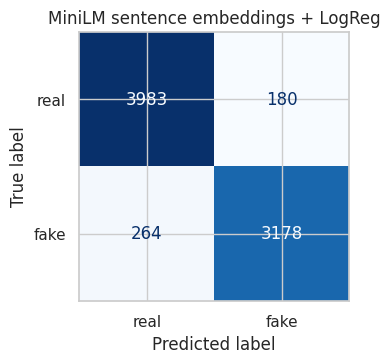

In [21]:
emb_clf = LogisticRegression(max_iter=3000, C=10)
cv_emb = cross_validate(emb_clf, E.loc[c_train].values, yc_train, cv=skf, scoring='f1', n_jobs=2)
print(f'{emb_name} + LogReg  CV F1 = {cv_emb["test_score"].mean():.4f} ± {cv_emb["test_score"].std():.4f}')
emb_clf.fit(E.loc[c_train].values, yc_train)
results[emb_name + ' + LogReg (cleaned)'] = evaluate(f'{emb_name} + LogReg', yc_test, emb_clf.predict(E.loc[c_test].values))

The averaged GloVe representation is clearly weaker than the tuned TF-IDF model with an F1 of about 0.94 against 0.99. This is expected for two reasons. Averaging word vectors throws away word order and gives frequent function words the same weight as rare telling words. It also blurs exactly the stylistic markers that TF-IDF exploits such as said on wednesday or the informal you and just. GloVe vectors were trained on Wikipedia and newswire so words that the two sources use in different ways end up close together in the embedding space.

The sentence transformer path is expected to do better than GloVe because it encodes word order and context. It reads only the first 256 tokens of each article though so on this dataset it may still fall short of TF-IDF which sees the whole text. The strongest option would be to fine tune DistilBERT end to end on the cleaned text since the model could then learn the style cues directly. That needs a GPU to finish in reasonable time. A key point is that a stronger model on this dataset will mostly become better at recognising the house style of Reuters so higher scores here would not mean better fact checking.

### Overall comparison

,accuracy,precision,recall,f1
baseline (raw title+text),0.9950,0.9974,0.9916,0.9945
subject only,1.0000,1.0000,1.0000,1.0000
date string only,1.0000,1.0000,1.0000,1.0000
cleaned title+text,0.9892,0.9930,0.9831,0.9880
tuned Passive Aggressive (cleaned),0.9929,0.9945,0.9898,0.9921
MiniLM sentence embeddings + LogReg (cleaned),0.9416,0.9464,0.9233,0.9347


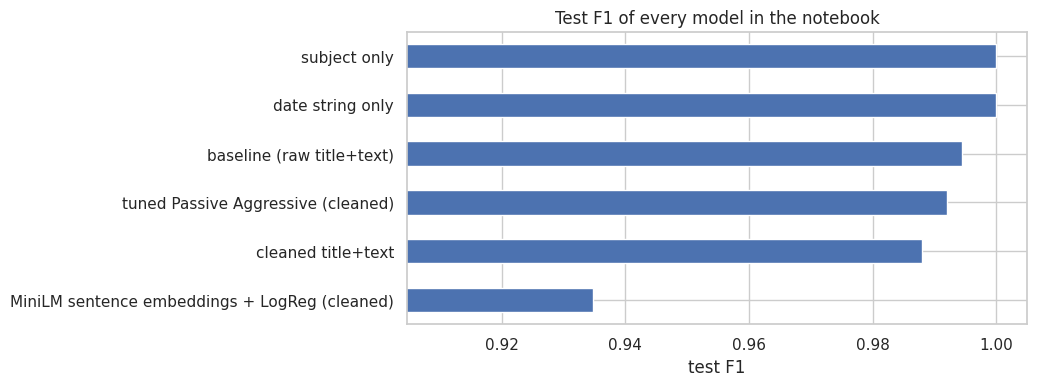

In [22]:
final = pd.DataFrame(results).T.round(4)
display(final)
ax = final['f1'].sort_values().plot.barh(figsize=(8, 3.8))
ax.set_xlim(final['f1'].min() - 0.03, 1.005); ax.set_xlabel('test F1')
ax.set_title('Test F1 of every model in the notebook'); plt.show()

## 7. Conclusions

**The data needed real cleaning before modelling.** The merged file has 44,898 articles. We removed 641 empty or malformed rows and 5,944 exact duplicates after normalisation and 255 near duplicates. That leaves 38,058 unique articles. Almost all duplicates were fake articles stored twice under two subject tags. Without this step copies of the same article would sit on both sides of the split and inflate the test score.

**The original baseline was too good to be true.** TF-IDF with Logistic Regression on the raw title and text reached an F1 of about 0.995. Its top features were the Reuters dateline and image credits and tweet links. None of these carry information about truthfulness.

**The metadata leaks completely.** Subject alone and the date string alone each give a perfect score of 1.0. Subject values never overlap between classes and the two sources format dates differently. Both columns were dropped.

**After removing the artifacts the task is still easy.** With the dateline and credits and links and title tags stripped the same Logistic Regression still reaches an F1 of about 0.988. The remaining signal is mostly writing style. Reuters writes said on wednesday and formal titles while the fake sites write in a conversational and opinionated voice.

**The linear models are close and Naive Bayes trails.** Under 5 fold cross validation Passive Aggressive and the linear SVM and Logistic Regression all score between about 0.983 and 0.987 in F1 with standard deviations near 0.001 to 0.002. Multinomial Naive Bayes reaches about 0.945. Training takes under a second per fold for every model and the vectorizer dominates the cost.

**Tuning helps slightly.** The randomised search over vectorizer and classifier settings found unigrams plus bigrams and 100,000 features with min_df of 5 and max_df of 0.9 and sublinear term frequency and C close to 0.6 as the best combination. Its cross validated F1 is about 0.987 and the held out test F1 is about 0.992.

**The body carries most of the signal.** In cross validation title only reaches about 0.92 in F1 and text only about 0.984 and title plus text about 0.987. The headline adds a small but consistent gain.

**Dense averaged word vectors do not beat TF-IDF here.** Averaged GloVe vectors with Logistic Regression reach about 0.94 in F1.

**Limitations.** Every real article comes from one publisher and one period. A model trained here learns to tell Reuters from a handful of partisan websites. It does not learn to check facts. Its performance on real news from other outlets and on fake news written in a neutral wire style would very likely be much lower. A fairer benchmark would draw both classes from many publishers and split the data by publisher so that no source appears in both training and test data.